# TITLE

## NAME & CLASS

Into --
- Where data comes from
- Timeframe of dataset (if noted in PEW) .... should confirm this later with teh survey start/end dates
- Who was sampled
- What each row/record represents
- What question we want to answer

PEW Research Center: TITLE OF THE DATASET
https://www.pewresearch.org/dataset/american-trends-panel-wave-137/


ATP W137 included two subsamples of U.S adults: 
1) Parents of at least one 18- to 34-year old with whom they are in contact (excluding children who are still in high-school) and 
2) 18-34 year old's (excluding those still in high school) who have at least one living parent with whom they are in contact. 


18-34 year old's who have at least one living parent were asked SCHLMOD – CLIVEPAR5. WEIGHT_W137_CHILD should be used for these questions.  Parents of at least one 18- to 34-year old were asked CHILDGRP – PMILESTONE3. WEIGHT_W137_PARENT should be used for these questions. 


Group
Parents of 18–34-year-olds 3,017

Adults 18-34-year-olds
who have living parents 1,495


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os
import subprocess, sys

df = pd.read_csv("ATP_W137.csv")

#print("\nChildren/Parents represented:")
#df[['QKEY', 'SCHLMOD_W137', 'CHILDTOTAL_W137']].count()

In [15]:
#describe the data (what columns, what a row represents, where it is from, etc.)
print("Full survey results:", df.shape)
parenting = df.copy()

fields_maintained = ['QKEY', 
'XSAMPLE_W137', #Flag to identify the two subsamples
'CHILD_AGE_1_RECODE_W137',     #What is {Child1}’s age?
'CHILD_GEND_1_W137',   #Does {Child1} identify as a man, a woman, or in some other way?
'DOV_CHILD_GENDER_W137',   #Selected child’s gender
'PSUCCESS_W137',   #How much do you think your child(ren)’s successes and failures reflect the job you have done as a parent?
'PPREPARE_W137',   #Overall, to what extent do you think you prepared your child(ren) to be an independent adult?
'PRATEREL_W137',   #How would you rate your relationship with your child overall?
'PFEEL_a_W137',    #Worried // Overall, thinking about how things are going in your child’s life, how often do you feel…
'PCINVOLV_W137',   #Thinking about how involved you are in your child’s day-to-day life, would you say you are…
'PMONITOR_W137',   #Do you ever track your child’s location through GPS apps or software?


'F_METRO', #Metropolitan area indicator
'F_CREGION',  #Census region
'F_CDIVISION', #Census division
'F_USR_SELFID',    # Self-identified Urban, Suburban, Rural (USR)
'F_AGECAT',    #Age category
'F_GENDER',    #Gender
'F_EDUCCAT',   #Education category
'F_EDUCCAT2',  #Education level category 2
'F_RACECMB',   #Combining Race
'F_PARTY_FINAL',   #Political party
'F_PARTYSUM_FINAL',    #Political party summary
'F_PARTYSUMIDEO_FINAL',    #Combining ideology and party identification
'F_INC_SDT1',  #Family income
'F_IDEO',  #Ideology
'F_INC_TIER2', #Income tier 3-way
'F_INTFREQ',   #Frequency of internet use
]

# Keep only the requested columns that exist in the dataframe
parenting_scope = parenting[[col for col in fields_maintained if col in parenting.columns]].copy()

parents = parenting_scope[parenting_scope['XSAMPLE_W137'] == 2]
parents.head()

print("\nParent Responses Only:", parents.shape)


Full survey results: (4512, 196)

Parent Responses Only: (3017, 27)


Details on which fields we maintained & that we scoped the dataset to just be out parent reponses, n = 3017

In [16]:
parents = parents.replace(99, np.nan)

labels = {
    'DOV_CHILD_GENDER_W137': {1: 'Son', 2: 'Daughter', 3: 'Other'},
    'CHILD_AGE_1_RECODE_W137': {1: 'Ages 18-24', 2: 'Ages 25-29', 3: 'Ages 30-34'},
    'PSUCCESS_W137': {1: 'A great deal', 2: 'A fair amount', 3: 'Some', 4: 'Not much', 5: 'Not at all'},
    'PPREPARE_W137': {1: 'A great deal', 2: 'A fair amount', 3: 'Some', 4: 'Not much', 5: 'Not at all'},
    'PRATEREL_W137': {1: 'Excellent', 2: 'Very good', 3: 'Good', 4: 'Fair', 5: 'Poor'},
    'PFEEL_a_W137': {1: 'Extremely often', 2: 'Very often', 3: 'Sometimes', 4: 'Rarely', 5: 'Never'},      # worried
    'PCINVOLV_W137': {1: 'More involved than like', 2: 'Less involved than like', 3: 'As involved as like'},
    'PMONITOR_W137': {1: 'Yes, frequently', 2: 'Yes, sometimes', 3: 'Yes, rarely', 4: 'No, never'},
    'F_GENDER': {1: 'Man', 2: 'Woman', 3: 'Other'},
    'F_USR_SELFID': {1: 'Urban', 2: 'Suburban', 3: 'Rural'},
    'F_INC_TIER2': {1: 'Lower income', 2: 'Middle income', 3: 'Upper income'},
}
# Friendlier names for the main analysis variables
names = {
    'DOV_CHILD_GENDER_W137': 'child_gender', 'CHILD_AGE_1_RECODE_W137': 'child_age',
    'PSUCCESS_W137': 'success_reflects_parent', 'PPREPARE_W137': 'prepared_independent',
    'PRATEREL_W137': 'relationship', 'PFEEL_a_W137': 'worried', 'PCINVOLV_W137': 'involvement',
    'PMONITOR_W137': 'gps_tracking', 'F_GENDER': 'parent_gender', 'F_USR_SELFID': 'community',
    'F_INC_TIER2': 'income_tier',
}

num = parents.rename(columns=names)
cat = num.copy()
for raw, mapping in labels.items():
    n = names[raw]
    cat[n] = pd.Categorical(num[n].map(mapping), categories=list(mapping.values()), ordered=True)

# Derived binary flags that are easier to compare across groups
cat['tracks_child_gps'] = np.where(num['gps_tracking'].isna(), np.nan, (num['gps_tracking'] <= 3).astype(float))
cat['often_worried'] = np.where(num['worried'].isna(), np.nan, (num['worried'] <= 2).astype(float))        # extremely/very often
cat['well_prepared'] = np.where(num['prepared_independent'].isna(), np.nan, (num['prepared_independent'] <= 2).astype(float))
cat['great_relationship'] = np.where(num['relationship'].isna(), np.nan, (num['relationship'] <= 2).astype(float))  # excellent/very good

core = ['child_gender', 'child_age', 'success_reflects_parent', 'prepared_independent',
        'relationship', 'worried', 'involvement', 'gps_tracking']
print("\nMissing values after recoding refusals:")
print(num[core].isnull().sum())

print("\nFirst few rows:\n", cat.head())



Missing values after recoding refusals:
child_gender                1
child_age                  40
success_reflects_parent     3
prepared_independent       30
relationship                3
worried                     8
involvement                 3
gps_tracking                5
dtype: int64

First few rows:
      QKEY  XSAMPLE_W137   child_age  CHILD_GEND_1_W137 child_gender  \
0  100598             2  Ages 18-24                2.0     Daughter   
2  103519             2  Ages 30-34                1.0     Daughter   
3  104727             2  Ages 30-34                1.0        Other   
4  106180             2  Ages 25-29                2.0     Daughter   
5  106590             2  Ages 25-29                1.0          Son   

  success_reflects_parent prepared_independent relationship          worried  \
0            A great deal         A great deal    Excellent        Sometimes   
2                    Some        A fair amount         Good  Extremely often   
3            A great 

Write up on why these nulls are okay with our analysis for now.

#filter to keep the following columns:

CPREPARE_W137   #Overall, to what extent do you think your parent(s) prepared you to be an independent adult?
CRATEREL_W137   #How would you rate your relationship with your parent overall?
CINVOLV_W137    #Thinking about your parent’s involvement in your day-to-day life, would you say they are …

CHILD_AGE_1_RECODE_W137     #What is {Child1}’s age?
CHILD_GEND_1_W137   #Does {Child1} identify as a man, a woman, or in some other way?
DOV_CHILD_GENDER_W137   #Selected child’s gender
PSUCCESS_W137   #How much do you think your child(ren)’s successes and failures reflect the job you have done as a parent?
PPREPARE_W137   #Overall, to what extent do you think you prepared your child(ren) to be an independent adult?
PRATEREL_W137   #How would you rate your relationship with your child overall?
PFEEL_a_W137    #Worried // Overall, thinking about how things are going in your child’s life, how often do you feel…
PCINVOLV_W137   #Thinking about how involved you are in your child’s day-to-day life, would you say you are…
PMONITOR_W137   #Do you ever track your child’s location through GPS apps or software?


F_METRO #Metropolitan area indicator
F_CREGION   #Census region
F_CDIVISION #Census division
F_USR_SELFID    # Self-identified Urban, Suburban, Rural (USR)
F_AGECAT    #Age category
F_GENDER    #Gender
F_EDUCCAT   #Education category
F_EDUCCAT2  #Education level category 2
F_RACECMB   #Combining Race
F_PARTY_FINAL   #Political party
F_PARTYSUM_FINAL    #Political party summary
F_PARTYSUMIDEO_FINAL    #Combining ideology and party identification
F_INC_SDT1  #Family income
F_IDEO  #Ideology
F_INC_TIER2 #Income tier 3-way
F_INTFREQ   #Frequency of internet use

In [17]:
#visualizations of the data (scatterplots, distribution of key variables, boxplot)
cat.info()

<class 'pandas.DataFrame'>
Index: 3017 entries, 0 to 4511
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   QKEY                     3017 non-null   int64   
 1   XSAMPLE_W137             3017 non-null   int64   
 2   child_age                2977 non-null   category
 3   CHILD_GEND_1_W137        3016 non-null   float64 
 4   child_gender             3016 non-null   category
 5   success_reflects_parent  3014 non-null   category
 6   prepared_independent     2987 non-null   category
 7   relationship             3014 non-null   category
 8   worried                  3009 non-null   category
 9   involvement              3014 non-null   category
 10  gps_tracking             3012 non-null   category
 11  F_METRO                  3014 non-null   float64 
 12  F_CREGION                3017 non-null   float64 
 13  F_CDIVISION              3017 non-null   float64 
 14  community               

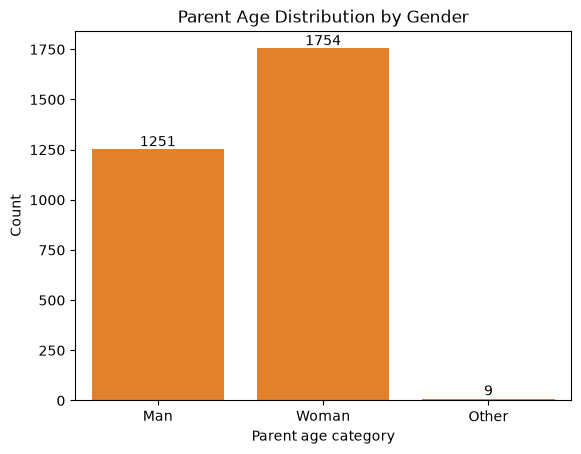

In [18]:
#Distribution of parents age & color by gender

sns.countplot(data=cat, x='parent_gender')
plt.xlabel('Parent age category')
plt.ylabel('Count')
plt.title('Parent Age Distribution by Gender')
ax = sns.countplot(data=cat, x='parent_gender')
ax.bar_label(ax.containers[0])
plt.show()

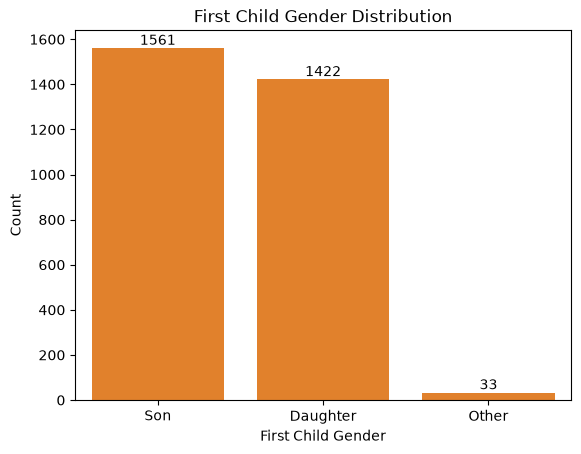

In [19]:
#Count of gender of child 1

sns.countplot(data=cat, x='child_gender')
plt.xlabel('First Child Gender')
plt.ylabel('Count')
plt.title('First Child Gender Distribution')
ax = sns.countplot(data=cat, x='child_gender')
ax.bar_label(ax.containers[0])
plt.show()

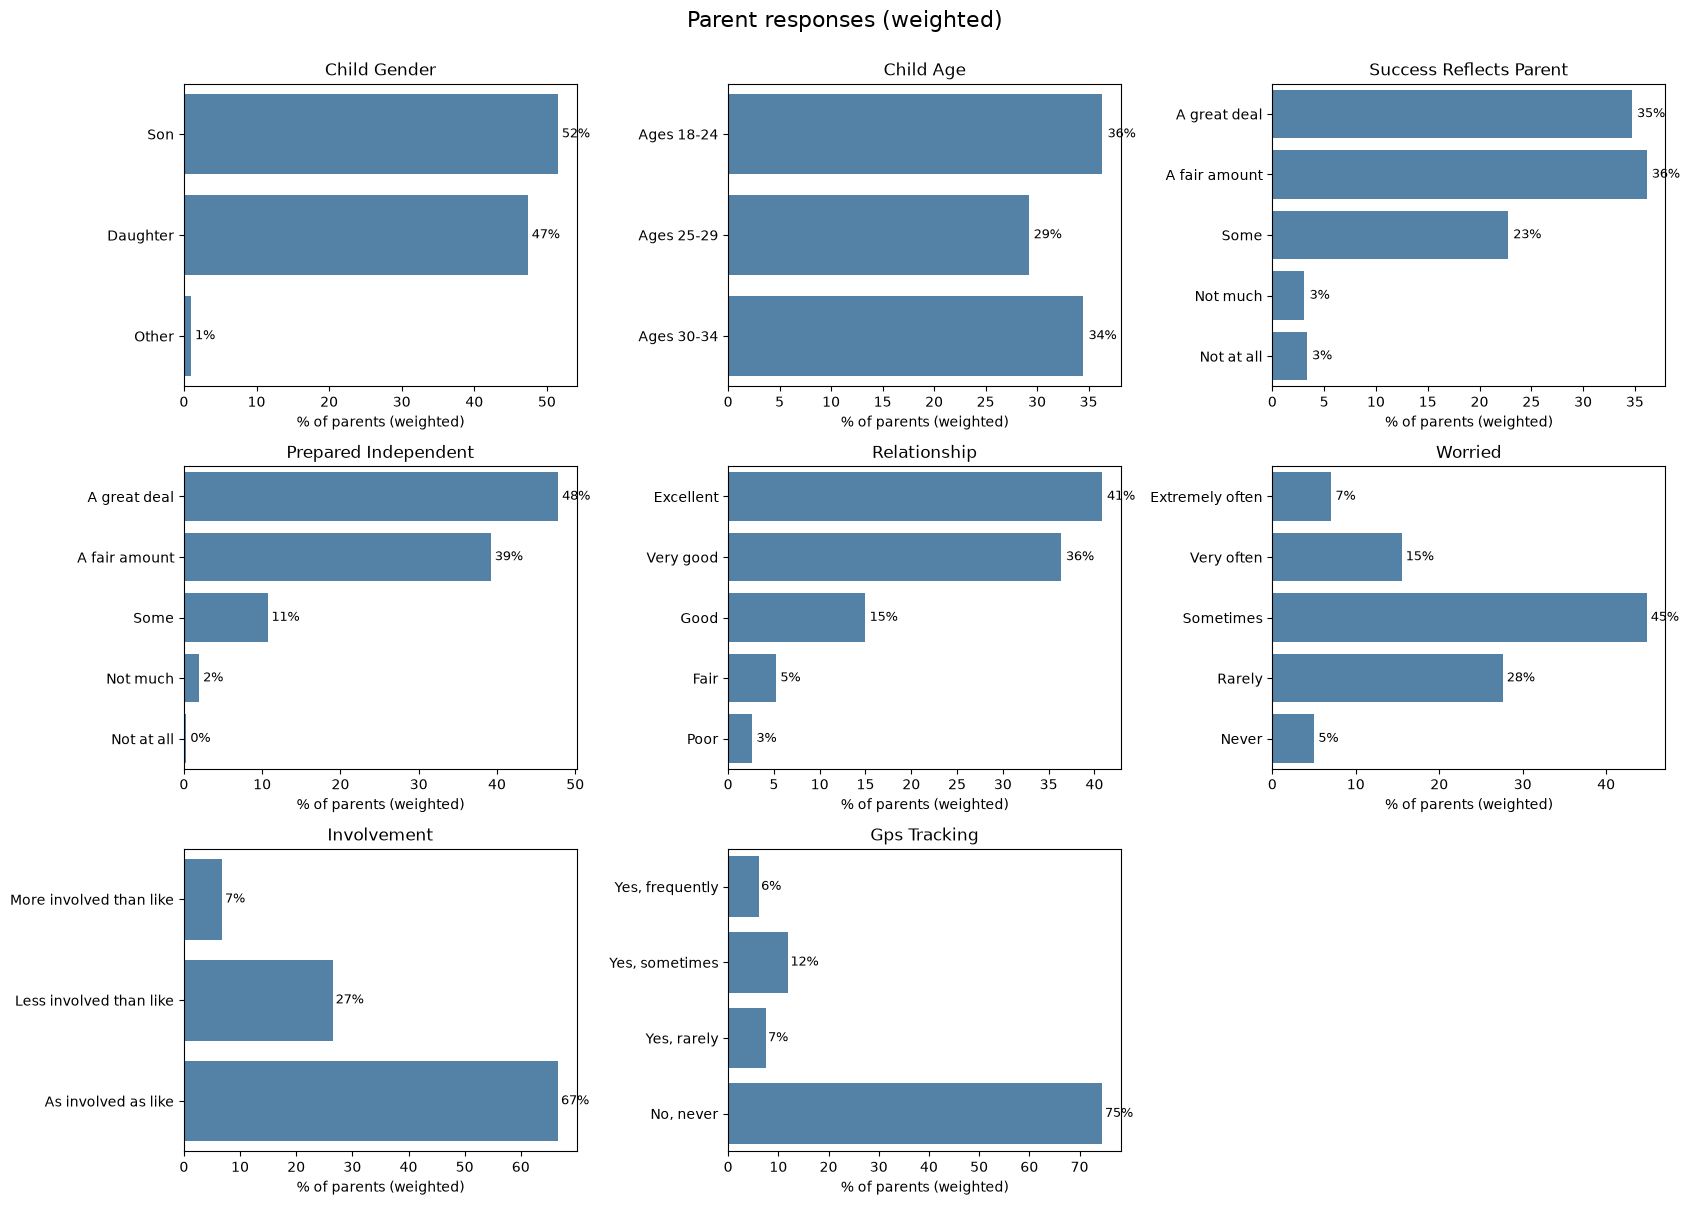

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(17, 12))
for ax, v in zip(axes.flat, core):
    # Add the parent survey weight and calculate weighted category percentages
    cat['w'] = df.loc[cat.index, 'WEIGHT_W137_PARENT']
    weighted = pd.DataFrame({
        'value': cat[v],
        'weight': cat['w']
    }).dropna()

    d = weighted.groupby('value', observed=True)['weight'].sum()
    d = d.div(d.sum()).mul(100).sort_index()
    sns.barplot(x=d.values, y=d.index.astype(str), ax=ax, color='steelblue')
    ax.set_title(v.replace('_', ' ').title()); ax.set_xlabel('% of parents (weighted)'); ax.set_ylabel('')
    for i, val in enumerate(d.values):
        ax.text(val + 0.5, i, f"{val:.0f}%", va='center', fontsize=9)
axes.flat[-1].axis('off')
plt.suptitle("Parent responses (weighted)", fontsize=16, y=1.0)
plt.tight_layout(); plt.show()



=== Worry: % of parents worried 'extremely/very often' ===


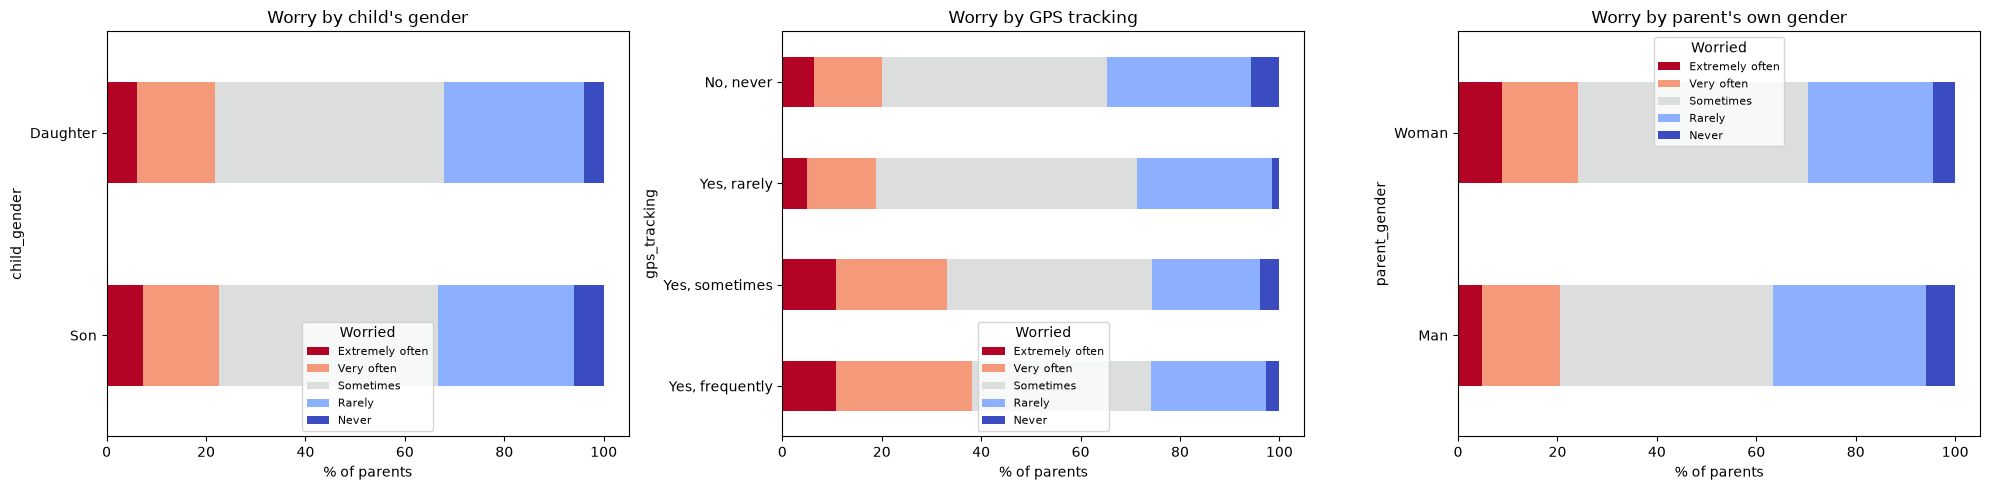

In [21]:
print("\n=== Worry: % of parents worried 'extremely/very often' ===")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
def wxtab(row, column):
    data = pd.DataFrame({
        row: cat[row],
        column: cat[column],
        'weight': df.loc[cat.index, 'WEIGHT_W137_PARENT']
    }).dropna()

    table = data.pivot_table(
        index=row, columns=column, values='weight',
        aggfunc='sum', observed=True, fill_value=0
    )
    return table.div(table.sum(axis=1), axis=0).mul(100)

wxtab('child_gender', 'worried').loc[['Son', 'Daughter']].plot(
    kind='barh', stacked=True, ax=axes[0], colormap='coolwarm_r'
)
axes[0].set_title("Worry by child's gender")
wxtab('gps_tracking', 'worried').plot(kind='barh', stacked=True, ax=axes[1], colormap='coolwarm_r')
axes[1].set_title("Worry by GPS tracking")
wxtab('parent_gender', 'worried').loc[['Man', 'Woman']].plot(kind='barh', stacked=True, ax=axes[2], colormap='coolwarm_r')
axes[2].set_title("Worry by parent's own gender")
for ax in axes: ax.set_xlabel('% of parents'); ax.legend(title='Worried', fontsize=8)
plt.tight_layout(); plt.show()



=== Prepared child for independence: % 'a great deal/a fair amount' ===


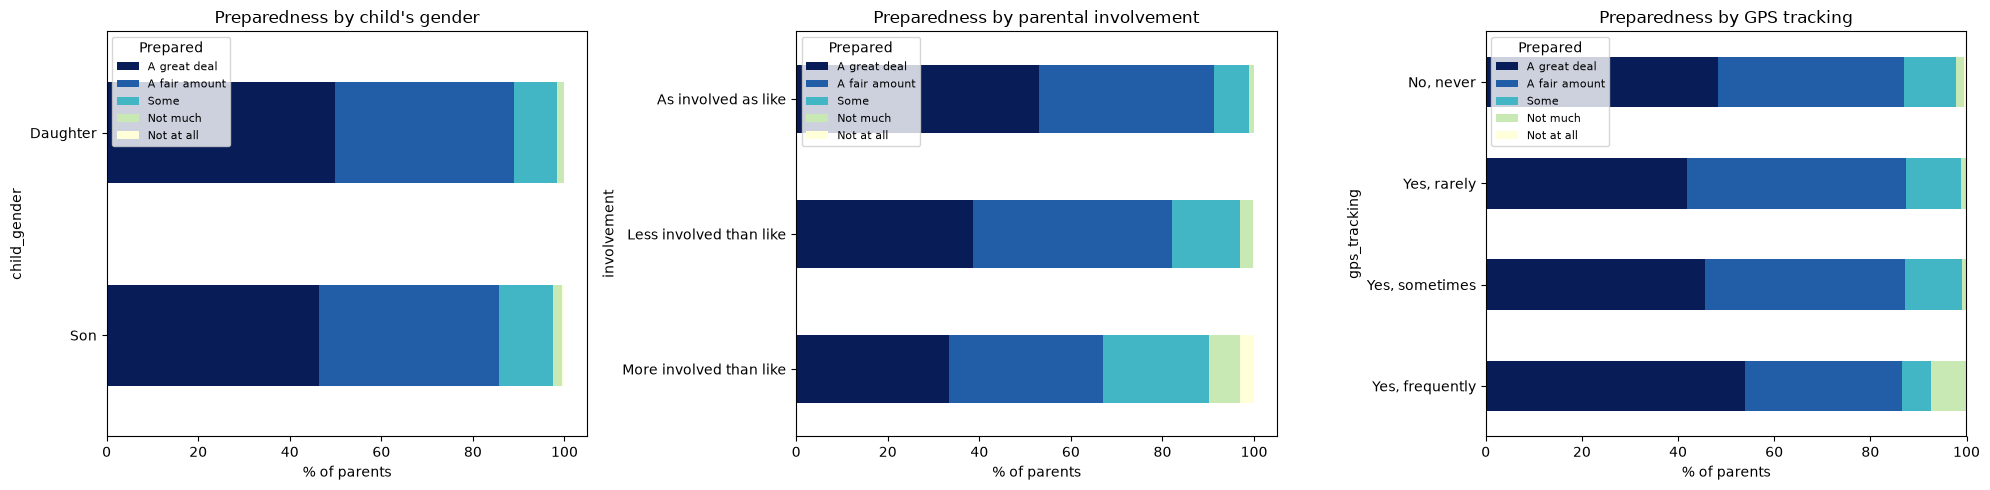

In [22]:
print("\n=== Prepared child for independence: % 'a great deal/a fair amount' ===")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
wxtab('child_gender', 'prepared_independent').loc[['Son', 'Daughter']].plot(kind='barh', stacked=True, ax=axes[0], colormap='YlGnBu_r')
axes[0].set_title("Preparedness by child's gender")
wxtab('involvement', 'prepared_independent').plot(kind='barh', stacked=True, ax=axes[1], colormap='YlGnBu_r')
axes[1].set_title("Preparedness by parental involvement")
wxtab('gps_tracking', 'prepared_independent').plot(kind='barh', stacked=True, ax=axes[2], colormap='YlGnBu_r')
axes[2].set_title("Preparedness by GPS tracking")
for ax in axes: ax.set_xlabel('% of parents'); ax.legend(title='Prepared', fontsize=8)
plt.tight_layout(); plt.show()



=== Relationship: % 'excellent/very good' ===


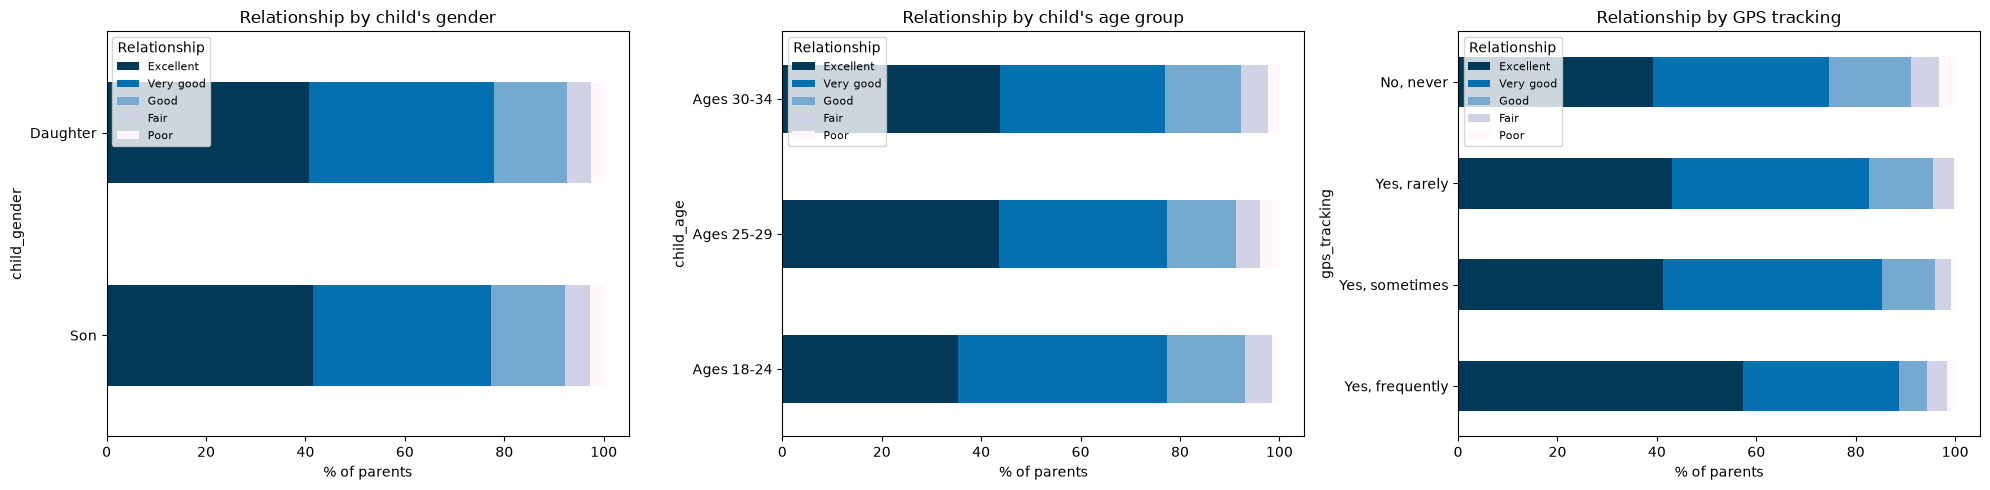

In [23]:
print("\n=== Relationship: % 'excellent/very good' ===")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
wxtab('child_gender', 'relationship').loc[['Son', 'Daughter']].plot(kind='barh', stacked=True, ax=axes[0], colormap='PuBu_r')
axes[0].set_title("Relationship by child's gender")
wxtab('child_age', 'relationship').plot(kind='barh', stacked=True, ax=axes[1], colormap='PuBu_r')
axes[1].set_title("Relationship by child's age group")
wxtab('gps_tracking', 'relationship').plot(kind='barh', stacked=True, ax=axes[2], colormap='PuBu_r')
axes[2].set_title("Relationship by GPS tracking")
for ax in axes: ax.set_xlabel('% of parents'); ax.legend(title='Relationship', fontsize=8)
plt.tight_layout(); plt.show()


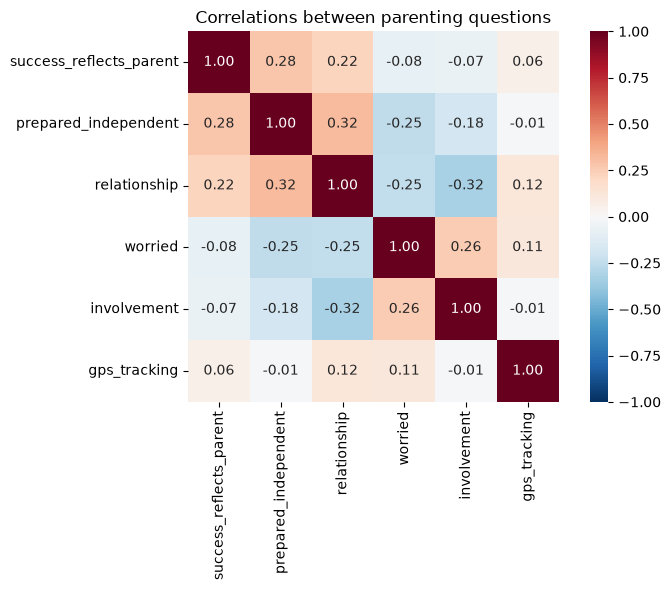

In [24]:
ord_cols = ['success_reflects_parent', 'prepared_independent', 'relationship', 'worried', 'involvement', 'gps_tracking']
corr = num[ord_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlations between parenting questions")
plt.tight_layout(); plt.show()
